<a href="https://colab.research.google.com/github/malithi19/Activity-4/blob/master/216140M_Big_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Real-World Big Data Analysis - Analyzing NYC Yellow Taxi Dataset for Optimization**
    

In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import BytesIO
import pyarrow.parquet as pq

# NYC Taxi Dataset URL (January 2025)
DATASET_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet"

# Download dataset directly
print(f"Downloading dataset from {DATASET_URL}")
response = requests.get(DATASET_URL)
file_bytes = BytesIO(response.content)

# Read parquet file into DataFrame
print("Loading dataset...")
df = pd.read_parquet(
    file_bytes
)
print(f"Loaded {len(df):,} records")

Loading dataset...
Loaded 3,475,226 records


In [2]:
# Show processed data
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [3]:
# Display basic dataset information
print(f"Dataset Shape: {df.shape}")
print(f"\nMemory Usage: {df.memory_usage(deep=True).sum() / (1024**2)} MB")
print("\nColumns and Data Types:")
print(df.dtypes)
print("\nFirst 5 Records:")
display(df.head())

# Additional summary statistics
print(f"\nDate Range: {df['tpep_pickup_datetime'].min()} to {df['tpep_pickup_datetime'].max()}")
print(f"Unique Pickup Locations: {df['PULocationID'].nunique()}")
print(f"Unique Dropoff Locations: {df['DOLocationID'].nunique()}")

Dataset Shape: (3475226, 20)

Memory Usage: 616.3112621307373 MB

Columns and Data Types:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

First 5 Records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0



Date Range: 2024-12-31 20:47:55 to 2025-02-01 00:00:44
Unique Pickup Locations: 261
Unique Dropoff Locations: 260


# **Data Observation**

In [4]:
df.isnull().sum()

,0
VendorID,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,540149
trip_distance,0
RatecodeID,540149
store_and_fwd_flag,540149
PULocationID,0
DOLocationID,0
payment_type,0


In [5]:
def get_data_overview(data):
    # Get column info
    num_data = data.select_dtypes(include=['float64', 'int64'])
    cat_data = data.select_dtypes(include=['object'])

    num_info = pd.DataFrame(num_data.dtypes.astype(str), columns=["Data Type"])
    num_info.index.name = "Column Name"
    num_info["No of Unique Values"] = num_data.nunique()
    num_info["No of Missing Values"] = num_data.isnull().sum()
    num_info["% of Missing Values"] = round((num_info["No of Missing Values"] / len(num_data)) * 100, 2)
    num_info["No of Duplicates"] = num_data.duplicated().sum()

    cat_info = pd.DataFrame(cat_data.dtypes.astype(str), columns=["Data Type"])
    cat_info.index.name = "Column Name"
    cat_info["No of Unique Values"] = cat_data.nunique()
    cat_info["No of Missing Values"] = cat_data.isnull().sum()
    cat_info["% of Missing Values"] = round((cat_info["No of Missing Values"] / len(cat_data)) * 100, 2)
    cat_info["No of Duplicates"] = cat_data.duplicated().sum()

    # Print overview table
    print(f"{'-'*120}\n{'Numeric Columns':^120}\n{'-'*120}\n{num_info.index.name:20} {'Data Type':10} {'No of Unique Values':20} {'No of Missing Values':20} {'% of Missing Values':20} {'No of Duplicates':20}\n{'-'*120}")
    for i in range(len(num_info)):
        print(f"{num_info.index[i]:20} {str(num_info.iloc[i, 0]):>10} {num_info.iloc[i, 1]:>20} {num_info.iloc[i, 2]:>20} {num_info.iloc[i, 3]:>20} {num_info.iloc[i, 4]:>20}")

    print(f"{'-'*120}\n{'Categorical Columns':^120}\n{'-'*120}\n{cat_info.index.name:20} {'Data Type':10} {'No of Unique Values':20} {'No of Missing Values':20} {'% of Missing Values':20} {'No of Duplicates':20}\n{'-'*120}")
    for i in range(len(cat_info)):
        print(f"{cat_info.index[i]:20} {str(cat_info.iloc[i, 0]):>10} {cat_info.iloc[i, 1]:>20} {cat_info.iloc[i, 2]:>20} {cat_info.iloc[i, 3]:>20} {cat_info.iloc[i, 4]:>20}")

get_data_overview(df)

------------------------------------------------------------------------------------------------------------------------
                                                    Numeric Columns                                                     
------------------------------------------------------------------------------------------------------------------------
Column Name          Data Type  No of Unique Values  No of Missing Values % of Missing Values  No of Duplicates    
------------------------------------------------------------------------------------------------------------------------
passenger_count         float64                   10               540149                15.54              2006278
trip_distance           float64                 4545                    0                  0.0              2006278
RatecodeID              float64                    7               540149                15.54              2006278
payment_type              int64                    6

In [6]:
def get_five_number_summary(data):
    num_data = data.select_dtypes(include=['float64', 'int64'])
    stats = num_data.describe().transpose()[['min', '25%', '50%', '75%', 'max']]
    stats['Range'] = stats['max'] - stats['min']
    stats.rename(columns={'50%': 'Median'}, inplace=True)

    # Print summary table
    print(f"{'-'*85}\n{'Column Name':20} {'Minimum':>10} {'1st Quartile':>15} {'Median':>15} {'3rd Quartile':>15} {'Maximum':>10} {'Range':>10}\n{'-'*85}")
    for i in range(len(stats)):
        print(f"{stats.index[i]:20} {stats.iloc[i, 0]:>10.2f} {stats.iloc[i, 1]:>15.2f} {stats.iloc[i, 2]:>15.2f} {stats.iloc[i, 3]:>15.2f} {stats.iloc[i, 4]:>10.2f} {stats.iloc[i, 5]:>10.2f}")

    #full describe output
    display(df.describe())

get_five_number_summary(df)

-------------------------------------------------------------------------------------
Column Name             Minimum    1st Quartile          Median    3rd Quartile    Maximum      Range
-------------------------------------------------------------------------------------
passenger_count            0.00            1.00            1.00            1.00       9.00       9.00
trip_distance              0.00            0.98            1.67            3.10  276423.57  276423.57
RatecodeID                 1.00            1.00            1.00            1.00      99.00      98.00
payment_type               0.00            1.00            1.00            1.00       5.00       5.00
fare_amount             -900.00            8.60           12.11           19.50  863372.12  864272.12
extra                     -7.50            0.00            0.00            2.50      15.00      22.50
mta_tax                   -0.50            0.50            0.50            0.50      10.50      11.00
tip_amount  

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3.475226e+06,3475226,3475226,2.935077e+06,3.475226e+06,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,2.935077e+06,2.935077e+06,3.475226e+06
mean,1.785428e+00,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,2.482535e+00,1.651916e+02,1.641252e+02,1.036623e+00,1.708180e+01,1.317737e+00,4.780991e-01,2.959813e+00,4.493081e-01,9.547946e-01,2.561129e+01,2.225237e+00,1.239111e-01,4.834093e-01
min,1.000000e+00,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-9.000000e+02,-7.500000e+00,-5.000000e-01,-8.600000e+01,-1.269400e+02,-1.000000e+00,-9.010000e+02,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.520000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.211000e+01,0.000000e+00,5.000000e-01,2.450000e+00,0.000000e+00,1.000000e+00,1.995000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.950000e+01,2.500000e+00,5.000000e-01,3.930000e+00,0.000000e+00,1.000000e+00,2.778000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,1.500000e+01,1.050000e+01,4.000000e+02,1.709400e+02,1.000000e+00,8.633804e+05,2.500000e+00,6.750000e+00,7.500000e-01
std,4.263282e-01,NaN,NaN,7.507503e-01,5.646016e+02,1.163277e+01,6.452948e+01,6.940169e+01,7.013334e-01,4.634729e+02,1.861509e+00,1.374623e-01,3.779681e+00,2.002582e+00,2.781938e-01,4.636585e+02,9.039932e-01,4.725090e-01,3.619307e-01


In [7]:
# Define custom color palette
my_palette = sns.color_palette("husl", 2)
sns.set_style("whitegrid")

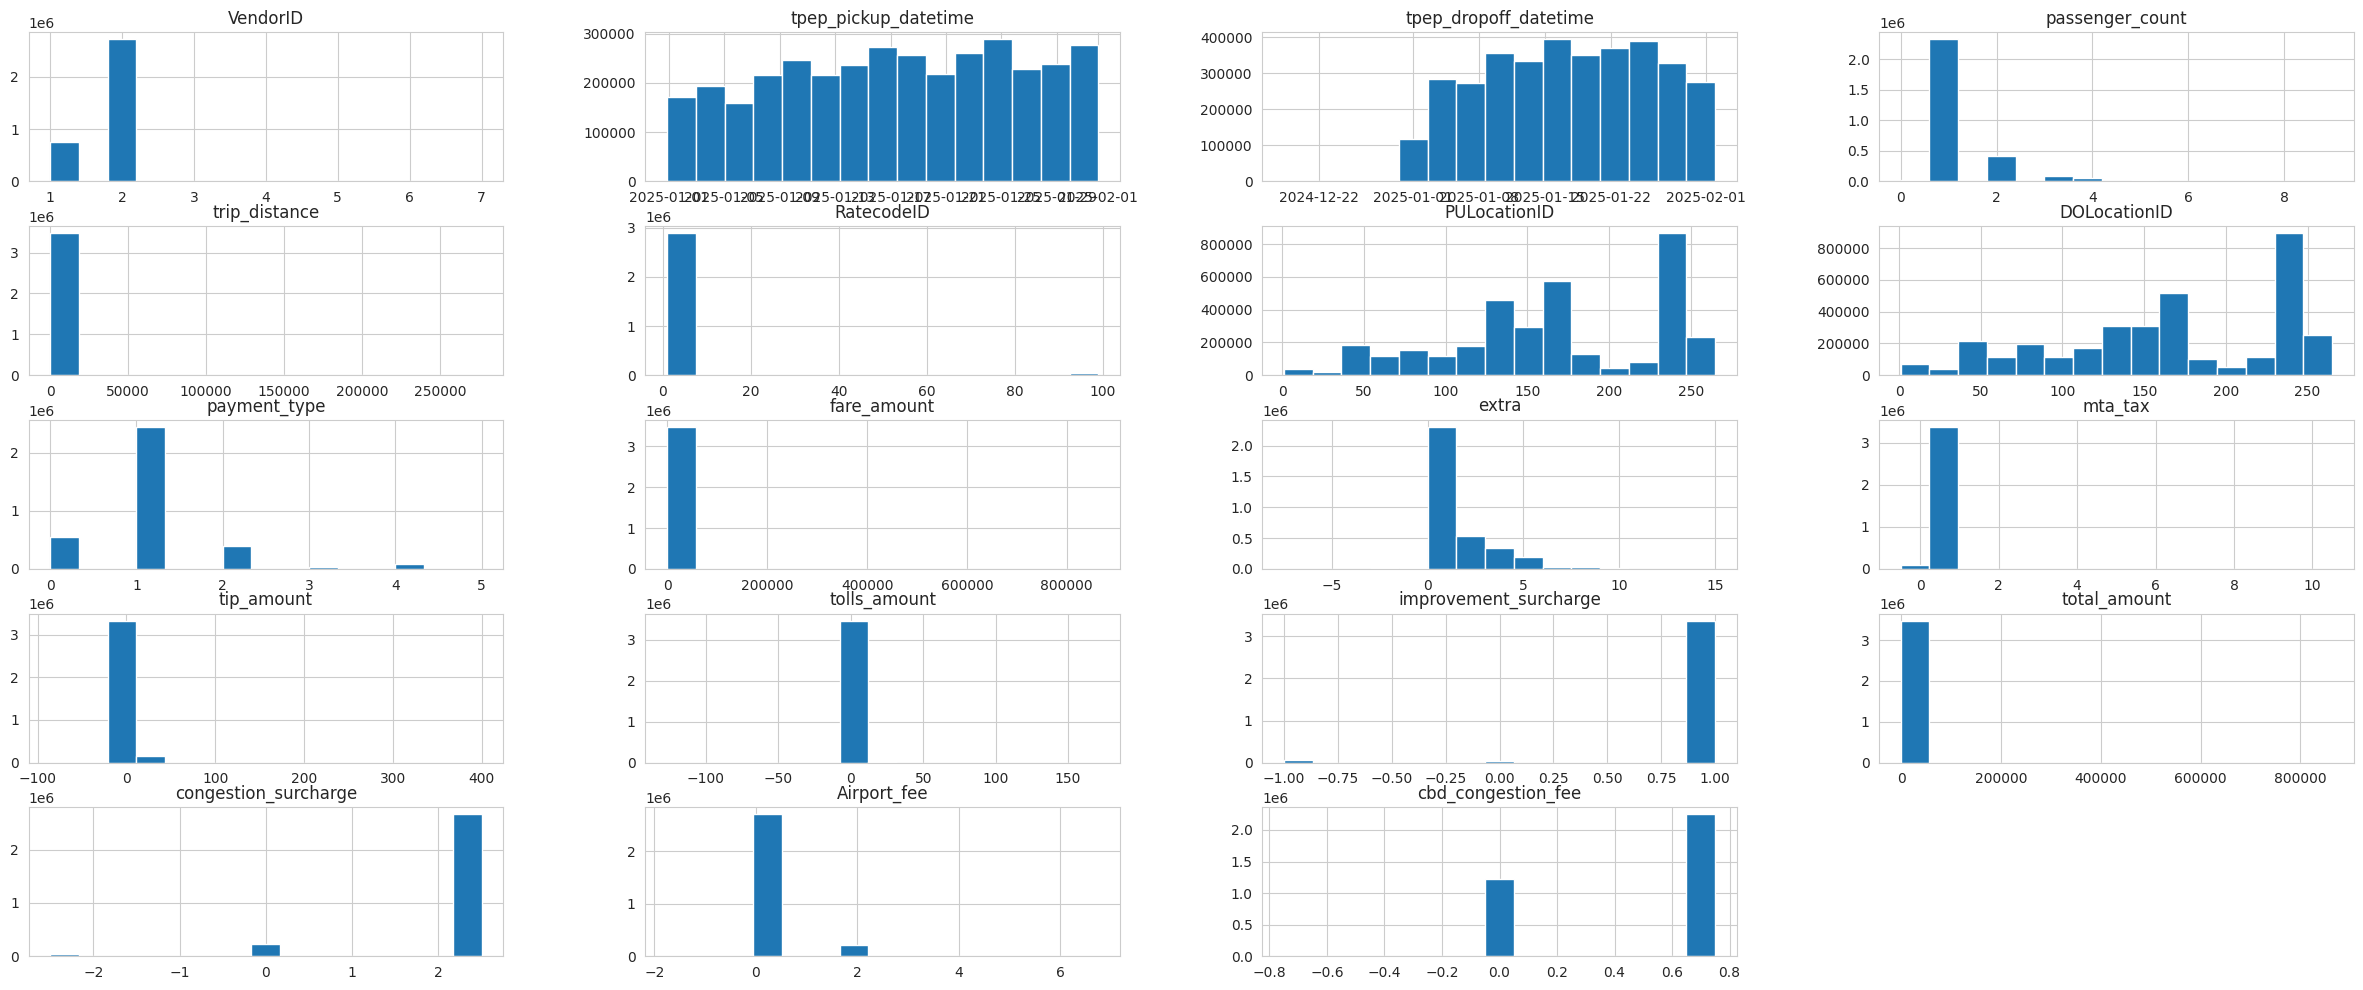

In [8]:
# Check the distribution of all the features
df.hist(figsize=(30,12),bins = 15)
plt.title("Features Distribution")
plt.show()

In [9]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee'],
      dtype='object')

## **Data Cleaning and Validation**

In [10]:
# Create a copy of the dataframe for cleaning and transformation
df_clean = df.copy()

# 1. Handle missing values
print("Missing values before handling:")
print(df_clean.isnull().sum())

# For numerical columns, impute with median (less sensitive to outliers)
numerical_cols = ['passenger_count', 'trip_distance', 'RatecodeID', 'fare_amount', 'extra', 'mta_tax',
                  'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount',
                  'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']

for col in numerical_cols:
    if df_clean[col].isnull().sum() > 0:
        median_val = df_clean[col].median()
        df_clean[col].fillna(median_val, inplace=True)

# For categorical columns, impute with mode
categorical_cols = ['store_and_fwd_flag', 'payment_type']
for col in categorical_cols:
    if df_clean[col].isnull().sum() > 0:
        mode_val = df_clean[col].mode()[0]
        df_clean[col].fillna(mode_val, inplace=True)

print("\nMissing values after handling:")
print(df_clean.isnull().sum())

# 2. Remove invalid trips based on business logic
# Remove trips with invalid fare, distance, or duration
initial_count = len(df_clean)

# Calculate trip duration in minutes
df_clean['trip_duration'] = (df_clean['tpep_dropoff_datetime'] - df_clean['tpep_pickup_datetime']).dt.total_seconds() / 60

# Filter out invalid records
df_clean = df_clean[
    (df_clean['fare_amount'] > 0) &
    (df_clean['fare_amount'] <= 500) & # Reasonable fare limit
    (df_clean['trip_distance'] > 0) &
    (df_clean['trip_distance'] <= 100) & # Reasonable distance limit
    (df_clean['trip_duration'] > 0) &
    (df_clean['trip_duration'] <= 180) & # Reasonable duration limit (3 hours)
    (df_clean['passenger_count'] > 0) &
    (df_clean['passenger_count'] <= 6) # Valid passenger count
]

print(f"Removed {initial_count - len(df_clean):,} invalid records ({((initial_count - len(df_clean))/initial_count*100):.2f}% of data)")
print(f"Clean dataset has {len(df_clean):,} records")

# 3. Remove geographical outliers (invalid location IDs)
valid_locations = range(1, 266) # Valid location IDs are 1-265
df_clean = df_clean[
    df_clean['PULocationID'].isin(valid_locations) &
    df_clean['DOLocationID'].isin(valid_locations)
]

print(f"Dataset after geographical validation: {len(df_clean):,} records")

Missing values before handling:
VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64


/tmp/ipython-input-801418066.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(median_val, inplace=True)
/tmp/ipython-input-801418066.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin


Missing values after handling:
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
Airport_fee              0
cbd_congestion_fee       0
dtype: int64
Removed 247,833 invalid records (7.13% of data)
Clean dataset has 3,227,393 records
Dataset after geographical validation: 3,227,393 records


## **Feature Engineering**

In [11]:
# 1. Temporal features
df_clean['pickup_hour'] = df_clean['tpep_pickup_datetime'].dt.hour
df_clean['pickup_day'] = df_clean['tpep_pickup_datetime'].dt.day
df_clean['pickup_dayofweek'] = df_clean['tpep_pickup_datetime'].dt.dayofweek # Monday=0, Sunday=6
df_clean['pickup_weekend'] = (df_clean['pickup_dayofweek'] >= 5).astype(int) # Weekend flag

# Create time of day categories
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Late Night'

df_clean['time_of_day'] = df_clean['pickup_hour'].apply(get_time_of_day)

# 2. Trip efficiency features
df_clean['speed_mph'] = (df_clean['trip_distance'] / (df_clean['trip_duration'] / 60)).round(2) # Miles per hour
# Handle infinite values from division by near-zero duration
df_clean['speed_mph'] = df_clean['speed_mph'].replace([np.inf, -np.inf], np.nan)
df_clean['speed_mph'].fillna(df_clean['speed_mph'].median(), inplace=True)

# 3. Financial efficiency features
df_clean['revenue_per_mile'] = (df_clean['total_amount'] / df_clean['trip_distance']).round(2)
df_clean['revenue_per_hour'] = (df_clean['total_amount'] / (df_clean['trip_duration'] / 60)).round(2)

# 4. Trip type classification
# Identify airport trips
airport_zones = [1, 132, 138]  # Newark, JFK, LaGuardia
df_clean['is_airport_trip'] = ((df_clean['PULocationID'].isin(airport_zones)) |
                              (df_clean['DOLocationID'].isin(airport_zones))).astype(int)

# Identify interstate trips (between Manhattan and other boroughs)
manhattan_zone = 1  # Assuming zone 1 is Manhattan (simplified)
df_clean['is_interborough'] = ((df_clean['PULocationID'] == manhattan_zone) !=
                              (df_clean['DOLocationID'] == manhattan_zone)).astype(int)

# 5. Payment type categorization
def get_payment_type(payment_code):
    if payment_code == 1:
        return 'Credit Card'
    elif payment_code == 2:
        return 'Cash'
    elif payment_code == 3:
        return 'No Charge'
    elif payment_code == 4:
        return 'Dispute'
    else:
        return 'Unknown'

df_clean['payment_category'] = df_clean['payment_type'].apply(get_payment_type)

# 6. Tip percentage analysis
df_clean['tip_percentage'] = (df_clean['tip_amount'] / df_clean['fare_amount'] * 100).round(2)
# Handle cases where fare_amount is 0
df_clean['tip_percentage'] = df_clean['tip_percentage'].replace([np.inf, -np.inf], 0)

print("Added new features:", ['trip_duration', 'pickup_hour', 'pickup_day', 'pickup_dayofweek',
                              'pickup_weekend', 'time_of_day', 'speed_mph', 'revenue_per_mile',
                              'revenue_per_hour', 'is_airport_trip', 'is_interborough',
                              'payment_category', 'tip_percentage'])

/tmp/ipython-input-2466225780.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['speed_mph'].fillna(df_clean['speed_mph'].median(), inplace=True)


Added new features: ['trip_duration', 'pickup_hour', 'pickup_day', 'pickup_dayofweek', 'pickup_weekend', 'time_of_day', 'speed_mph', 'revenue_per_mile', 'revenue_per_hour', 'is_airport_trip', 'is_interborough', 'payment_category', 'tip_percentage']


## **Data Encoding and Transformation**

In [12]:
# 1. Convert categorical variables to appropriate data types
df_clean['VendorID'] = df_clean['VendorID'].astype('category')
df_clean['RatecodeID'] = df_clean['RatecodeID'].astype('category')
df_clean['store_and_fwd_flag'] = df_clean['store_and_fwd_flag'].astype('category')
df_clean['PULocationID'] = df_clean['PULocationID'].astype('category')
df_clean['DOLocationID'] = df_clean['DOLocationID'].astype('category')
df_clean['payment_category'] = df_clean['payment_category'].astype('category')
df_clean['time_of_day'] = df_clean['time_of_day'].astype('category')

# 2. Create aggregated features for efficient analysis
# Create pickup hour and location combination (for demand heatmaps)
df_clean['hour_location'] = (df_clean['pickup_hour'].astype(str) + "_" +
                            df_clean['PULocationID'].astype(str))

# 3. Optimize data types to reduce memory usage
def optimize_memory_usage(df):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        col_min = df[col].min()
        col_max = df[col].max()

        # Downcast numeric columns
        if np.issubdtype(df[col].dtype, np.integer):
            if col_min > np.iinfo(np.int8).min and col_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif col_min > np.iinfo(np.int16).min and col_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif col_min > np.iinfo(np.int32).min and col_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
        else:
            if col_min > np.finfo(np.float16).min and col_max < np.finfo(np.float16).max:
                df[col] = df[col].astype(np.float16)
            elif col_min > np.finfo(np.float32).min and col_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)

    return df

print(f"Memory usage before optimization: {df_clean.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df_clean = optimize_memory_usage(df_clean)
print(f"Memory usage after optimization: {df_clean.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# Display final dataset info
print("\nFinal dataset shape:", df_clean.shape)
print("\nSample of engineered features:")
display(df_clean[['tpep_pickup_datetime', 'PULocationID', 'DOLocationID', 'trip_duration',
                 'pickup_hour', 'time_of_day', 'speed_mph', 'revenue_per_mile',
                 'is_airport_trip', 'payment_category', 'tip_percentage']].head(10))

Memory usage before optimization: 823.76 MB


/tmp/ipython-input-2199676428.py:31: RuntimeWarning: overflow encountered in cast
  if col_min > np.finfo(np.float16).min and col_max < np.finfo(np.float16).max:
/tmp/ipython-input-2199676428.py:31: RuntimeWarning: overflow encountered in cast
  if col_min > np.finfo(np.float16).min and col_max < np.finfo(np.float16).max:
/tmp/ipython-input-2199676428.py:31: RuntimeWarning: overflow encountered in cast
  if col_min > np.finfo(np.float16).min and col_max < np.finfo(np.float16).max:


Memory usage after optimization: 414.40 MB

Final dataset shape: (3227393, 34)

Sample of engineered features:


/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,tpep_pickup_datetime,PULocationID,DOLocationID,trip_duration,pickup_hour,time_of_day,speed_mph,revenue_per_mile,is_airport_trip,payment_category,tip_percentage
0,2025-01-01 00:18:38,229,237,8.351562,0,Late Night,11.500000,11.250000,0,Credit Card,30.000000
1,2025-01-01 00:32:40,236,237,2.550781,0,Late Night,11.760000,24.234375,0,Credit Card,39.610001
2,2025-01-01 00:44:04,141,141,1.950195,0,Late Night,18.459999,20.171875,0,Credit Card,39.220001
3,2025-01-01 00:14:27,244,244,5.566406,0,Late Night,5.600000,18.656250,0,Cash,0.000000
4,2025-01-01 00:21:34,244,116,3.533203,0,Late Night,11.210000,12.578125,0,Cash,0.000000
5,2025-01-01 00:48:24,239,68,20.031250,0,Late Night,7.880000,9.156250,0,Cash,0.000000
9,2025-01-01 00:00:02,237,262,9.570312,0,Late Night,10.720000,9.593750,0,Cash,0.000000
10,2025-01-01 00:20:28,237,75,7.601562,0,Late Night,18.080000,7.160156,0,Cash,0.000000
11,2025-01-01 00:33:58,263,236,3.416016,0,Late Night,9.830000,23.140625,0,Credit Card,37.240002
12,2025-01-01 00:42:40,236,151,12.968750,0,Late Night,9.210000,9.648438,0,Cash,0.000000


# **EDA**

Summary Statistics and Initial Data Overview

In [13]:
df_clean.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee', 'trip_duration', 'pickup_hour', 'pickup_day',
       'pickup_dayofweek', 'pickup_weekend', 'time_of_day', 'speed_mph',
       'revenue_per_mile', 'revenue_per_hour', 'is_airport_trip',
       'is_interborough', 'payment_category', 'tip_percentage',
       'hour_location'],
      dtype='object')

In [14]:
df_clean.dtypes

,0
VendorID,category
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float16
trip_distance,float16
RatecodeID,category
store_and_fwd_flag,category
PULocationID,category
DOLocationID,category
payment_type,int8


In [15]:
# Create a copy of the dataframe with appropriate data types for summary statistics
df_summary = df_clean[['trip_distance', 'fare_amount', 'tip_amount', 'trip_duration', 'total_amount', 'passenger_count']].copy()

# Convert to appropriate data types to avoid overflow
df_summary = df_summary.astype({
    'trip_distance': 'float32',
    'fare_amount': 'float32',
    'tip_amount': 'float32',
    'trip_duration': 'float32',
    'total_amount': 'float32',
    'passenger_count': 'int8'
})

# 1. Overview of Cleaned Data
print("CLEANED DATASET OVERVIEW")
print("=" * 50)
print(f"Total Records: {len(df_clean):,}")
print(f"Date Range: {df_clean['tpep_pickup_datetime'].min().date()} to {df_clean['tpep_dropoff_datetime'].max().date()}")
print(f"Features: {df_clean.shape[1]}")
print(f"Memory Usage: {df_clean.memory_usage(deep=True).sum() / (1024**2):.2f} MB\n")

# 2. Key Numerical Summaries
print("KEY NUMERICAL SUMMARY (Cleaned Data)")
print("=" * 50)
summary_stats = df_summary.describe()
display(summary_stats.round(2))

# 3. Key Categorical Summaries
print("\nPASSENGER COUNT DISTRIBUTION")
print("=" * 50)
passenger_counts = df_clean['passenger_count'].value_counts().sort_index()
for count, num_trips in passenger_counts.items():
    print(f"{int(count)} passenger(s): {num_trips:>7,} trips ({num_trips/len(df_clean)*100:>5.1f}%)")

CLEANED DATASET OVERVIEW
Total Records: 3,227,393
Date Range: 2024-12-31 to 2025-02-01
Features: 34
Memory Usage: 414.40 MB

KEY NUMERICAL SUMMARY (Cleaned Data)


,trip_distance,fare_amount,tip_amount,trip_duration,total_amount,passenger_count
count,3227393.00,3227393.00,3227393.00,3227393.00,3227393.00,3227393.00
mean,3.17,17.96,3.12,14.69,26.82,1.27
std,4.14,16.18,3.72,11.33,20.36,0.70
min,0.01,0.01,0.00,0.02,0.00,1.00
25%,1.01,8.60,0.00,7.33,15.95,1.00
50%,1.70,12.80,2.59,11.70,20.38,1.00
75%,3.15,19.80,4.00,18.33,28.25,1.00
max,97.56,500.00,400.00,180.00,603.00,6.00



PASSENGER COUNT DISTRIBUTION
1 passenger(s): 2,661,955 trips ( 82.5%)
2 passenger(s): 393,573 trips ( 12.2%)
3 passenger(s):  87,755 trips (  2.7%)
4 passenger(s):  54,744 trips (  1.7%)
5 passenger(s):  17,539 trips (  0.5%)
6 passenger(s):  11,827 trips (  0.4%)


Temporal Patterns and Demand Trends

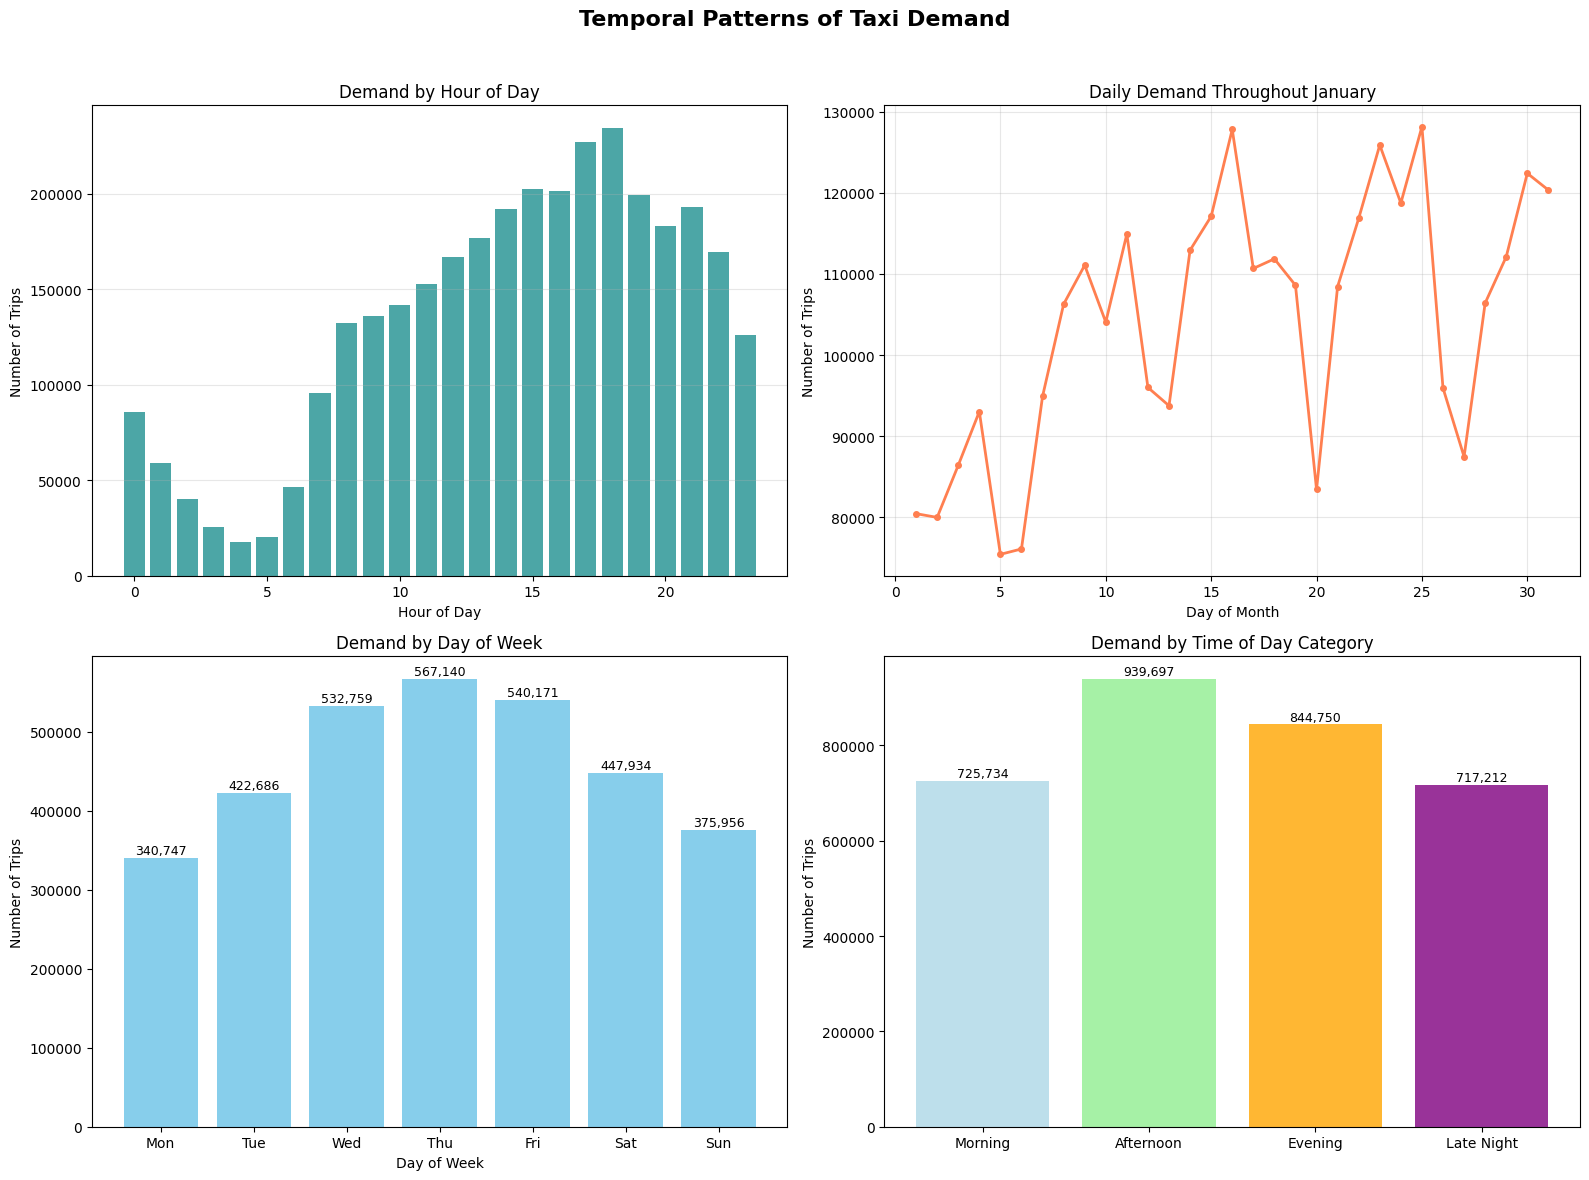

In [16]:
# Set the visual style
plt.style.use('default')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Temporal Patterns of Taxi Demand', fontsize=16, fontweight='bold')

# 1. Hourly Demand
hourly_demand = df_clean['pickup_hour'].value_counts().sort_index()
axes[0, 0].bar(hourly_demand.index, hourly_demand.values, color='teal', alpha=0.7)
axes[0, 0].set_title('Demand by Hour of Day')
axes[0, 0].set_xlabel('Hour of Day')
axes[0, 0].set_ylabel('Number of Trips')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Daily Demand (Across January)
daily_demand = df_clean['pickup_day'].value_counts().sort_index()
axes[0, 1].plot(daily_demand.index, daily_demand.values, marker='o', linestyle='-', linewidth=2, markersize=4, color='coral')
axes[0, 1].set_title('Daily Demand Throughout January')
axes[0, 1].set_xlabel('Day of Month')
axes[0, 1].set_ylabel('Number of Trips')
axes[0, 1].grid(alpha=0.3)

# 3. Day-of-Week Demand
day_of_week_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
dow_demand = df_clean['pickup_dayofweek'].value_counts().sort_index()
dow_demand.index = dow_demand.index.map(day_of_week_map)
axes[1, 0].bar(dow_demand.index, dow_demand.values, color='skyblue')
axes[1, 0].set_title('Demand by Day of Week')
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Number of Trips')
for i, v in enumerate(dow_demand.values):
    axes[1, 0].text(i, v + 1000, f'{v:,}', ha='center', va='bottom', fontsize=9)

# 4. Time-of-Day Category Demand
time_of_day_order = ['Morning', 'Afternoon', 'Evening', 'Late Night']
tod_demand = df_clean['time_of_day'].value_counts()[time_of_day_order]
axes[1, 1].bar(tod_demand.index, tod_demand.values, color=['lightblue', 'lightgreen', 'orange', 'purple'], alpha=0.8)
axes[1, 1].set_title('Demand by Time of Day Category')
axes[1, 1].set_ylabel('Number of Trips')
for i, v in enumerate(tod_demand.values):
    axes[1, 1].text(i, v + 1000, f'{v:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to make room for the main title
plt.show()

Spatial Analysis and Geographic Hotspots

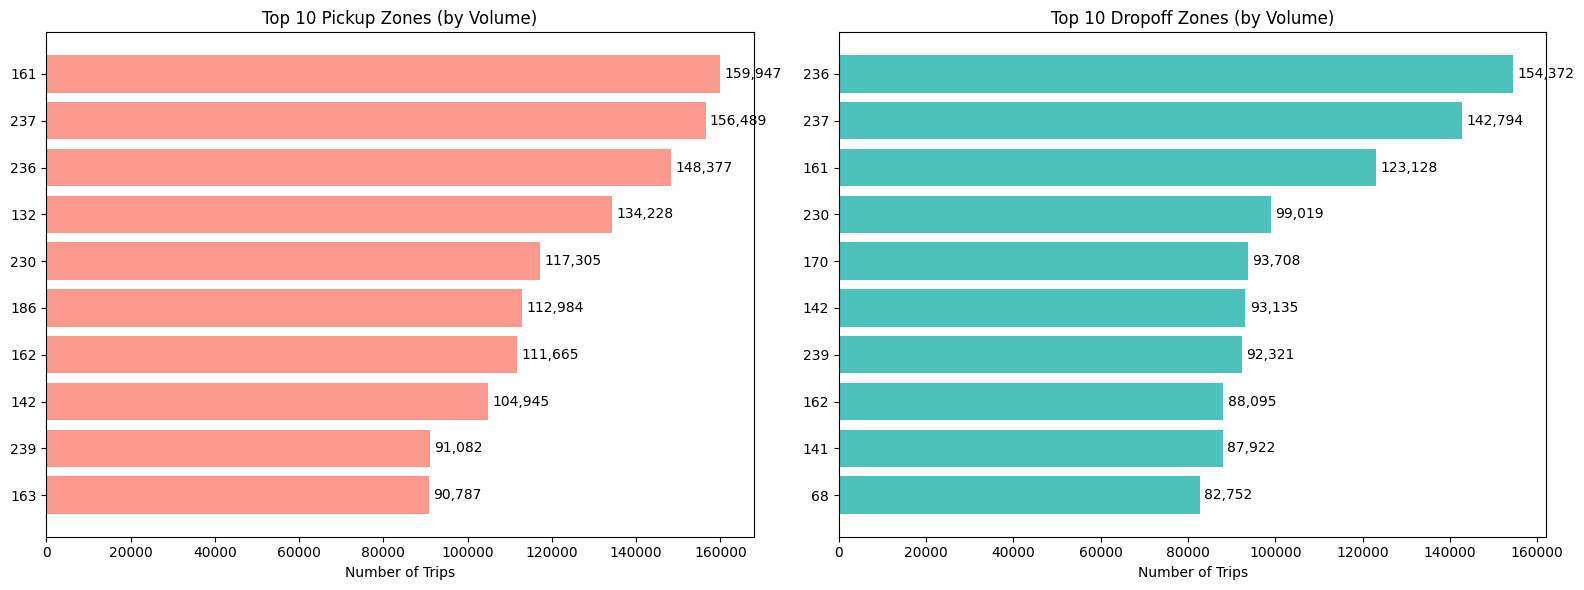


AIRPORT TRIP ANALYSIS
Number of Airport Trips: 275,625
Percentage of Total Trips: 8.54%
Average Fare (Airport Trips): $77.19
Average Fare (Non-Airport Trips): $22.12
Median Fare (Airport Trips): $77.06
Median Fare (Non-Airport Trips): $19.59
Average Distance (Airport Trips): 13.35 miles
Average Distance (Non-Airport Trips): 2.22 miles


In [17]:
# Analyze Top Zones
top_pickup_zones = df_clean['PULocationID'].value_counts().head(10)
top_dropoff_zones = df_clean['DOLocationID'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top Pickup Zones
axes[0].barh(range(10, 0, -1), top_pickup_zones.values, color='salmon', alpha=0.8) # Using range for positioning
axes[0].set_yticks(range(1, 11))
axes[0].set_yticklabels(top_pickup_zones.index[::-1]) # Reverse index to have highest at top
axes[0].set_title('Top 10 Pickup Zones (by Volume)')
axes[0].set_xlabel('Number of Trips')
for i, v in enumerate(top_pickup_zones.values[::-1]):
    axes[0].text(v + 1000, i+1, f'{v:,}', ha='left', va='center')

# Top Dropoff Zones
axes[1].barh(range(10, 0, -1), top_dropoff_zones.values, color='lightseagreen', alpha=0.8)
axes[1].set_yticks(range(1, 11))
axes[1].set_yticklabels(top_dropoff_zones.index[::-1])
axes[1].set_title('Top 10 Dropoff Zones (by Volume)')
axes[1].set_xlabel('Number of Trips')
for i, v in enumerate(top_dropoff_zones.values[::-1]):
    axes[1].text(v + 1000, i+1, f'{v:,}', ha='left', va='center')

plt.tight_layout()
plt.show()

# Analyze Airport Trips
print(f"\nAIRPORT TRIP ANALYSIS")
print("=" * 30)
print(f"Number of Airport Trips: {df_clean['is_airport_trip'].sum():,}")
print(f"Percentage of Total Trips: {(df_clean['is_airport_trip'].sum() / len(df_clean) * 100):.2f}%")

# Convert to float64 to avoid calculation issues before calculating means
airport_trips = df_clean[df_clean['is_airport_trip'] == 1]
non_airport_trips = df_clean[df_clean['is_airport_trip'] == 0]

# Calculate averages with higher precision
avg_fare_airport = airport_trips['total_amount'].astype('float64').mean()
avg_fare_non_airport = non_airport_trips['total_amount'].astype('float64').mean()

print(f"Average Fare (Airport Trips): ${avg_fare_airport:.2f}")
print(f"Average Fare (Non-Airport Trips): ${avg_fare_non_airport:.2f}")

# Additional insights
median_fare_airport = airport_trips['total_amount'].astype('float64').median()
median_fare_non_airport = non_airport_trips['total_amount'].astype('float64').median()
print(f"Median Fare (Airport Trips): ${median_fare_airport:.2f}")
print(f"Median Fare (Non-Airport Trips): ${median_fare_non_airport:.2f}")

# Compare trip distances
avg_distance_airport = airport_trips['trip_distance'].astype('float64').mean()
avg_distance_non_airport = non_airport_trips['trip_distance'].astype('float64').mean()
print(f"Average Distance (Airport Trips): {avg_distance_airport:.2f} miles")
print(f"Average Distance (Non-Airport Trips): {avg_distance_non_airport:.2f} miles")

Financial Analysis and Revenue Patterns

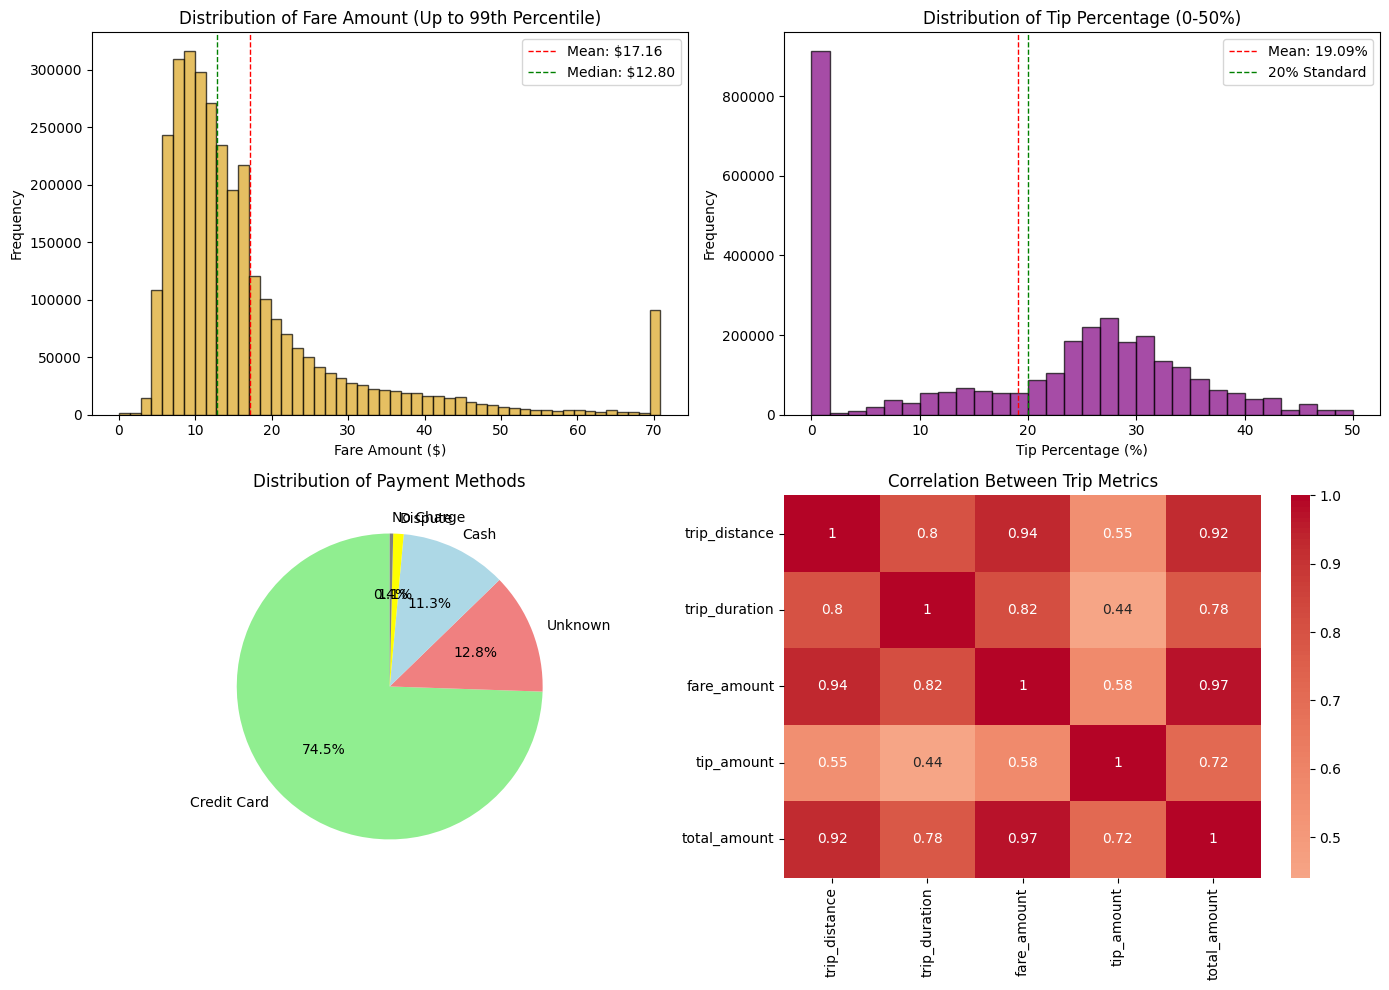

In [18]:
# Create a figure for financial distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Fare Amount Distribution (Focus on 99% of data to exclude extreme outliers)
fare_filtered = df_clean[df_clean['fare_amount'] <= df_clean['fare_amount'].quantile(0.99)]

# Convert to float64 to avoid calculation issues
fare_values = fare_filtered['fare_amount'].astype('float64')

# Calculate statistics with higher precision
mean_fare = fare_values.mean()
median_fare = fare_values.median()

axes[0, 0].hist(fare_values, bins=50, color='goldenrod', alpha=0.7, edgecolor='black')
axes[0, 0].set_title('Distribution of Fare Amount (Up to 99th Percentile)')
axes[0, 0].set_xlabel('Fare Amount ($)')
axes[0, 0].set_ylabel('Frequency')

# Only add lines if values are valid
if not np.isnan(mean_fare):
    axes[0, 0].axvline(mean_fare, color='red', linestyle='dashed', linewidth=1,
                      label=f'Mean: ${mean_fare:.2f}')
if not np.isnan(median_fare):
    axes[0, 0].axvline(median_fare, color='green', linestyle='dashed', linewidth=1,
                      label=f'Median: ${median_fare:.2f}')

axes[0, 0].legend()

# 2. Tip Percentage Distribution
tip_pct_filtered = df_clean[(df_clean['tip_percentage'] >= 0) & (df_clean['tip_percentage'] <= 50)] # Filter out extremes
axes[0, 1].hist(tip_pct_filtered['tip_percentage'], bins=30, color='purple', alpha=0.7, edgecolor='black')
axes[0, 1].set_title('Distribution of Tip Percentage (0-50%)')
axes[0, 1].set_xlabel('Tip Percentage (%)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].axvline(tip_pct_filtered['tip_percentage'].mean(), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {tip_pct_filtered["tip_percentage"].mean():.2f}%')
axes[0, 1].axvline(20, color='green', linestyle='dashed', linewidth=1, label='20% Standard')
axes[0, 1].legend()

# 3. Payment Type Distribution
payment_counts = df_clean['payment_category'].value_counts()
axes[1, 0].pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%', startangle=90, colors=['lightgreen', 'lightcoral', 'lightblue', 'yellow', 'grey'])
axes[1, 0].set_title('Distribution of Payment Methods')

# 4. Correlation Heatmap
corr_matrix = df_clean[['trip_distance', 'trip_duration', 'fare_amount', 'tip_amount', 'total_amount']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('Correlation Between Trip Metrics')

plt.tight_layout()
plt.show()

Payment Method Analysis

PAYMENT METHOD ANALYSIS


/tmp/ipython-input-1905869533.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  payment_analysis = df_clean.groupby('payment_category').agg({


,total_amount,tip_amount,tip_percentage,trip_count,percentage_of_trips
payment_category,,,,,
Cash,23.600000,0.00,0.000000,363731,11.27
Credit Card,27.950001,4.10,26.299999,2403313,74.47
Dispute,27.549999,0.01,0.030000,35451,1.10
No Charge,24.180000,0.00,0.020000,11743,0.36
Unknown,23.150000,0.55,2.740000,413155,12.80


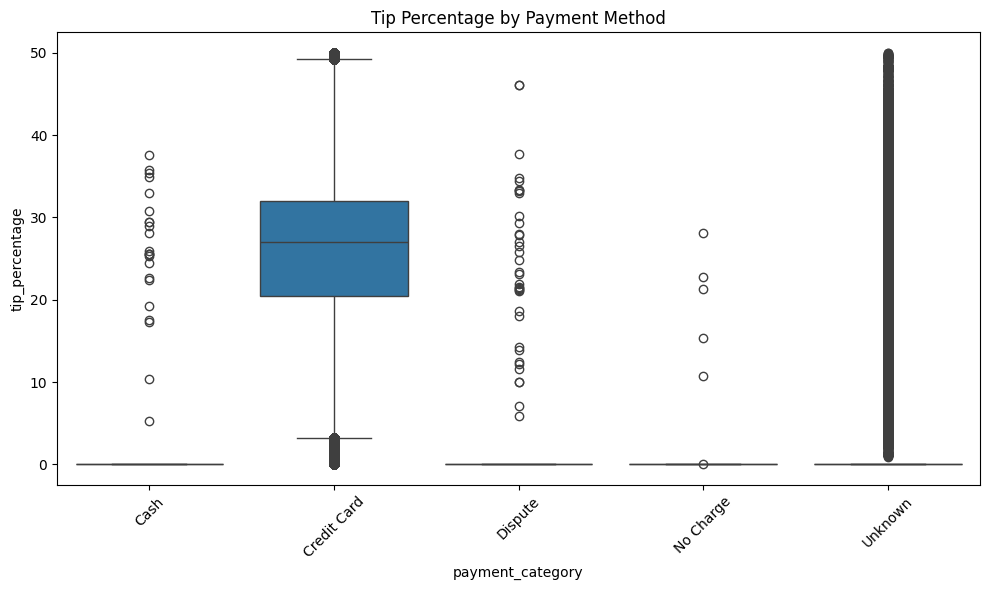

In [19]:
# Analyze payment methods in detail
payment_analysis = df_clean.groupby('payment_category').agg({
    'total_amount': 'mean',
    'tip_amount': 'mean',
    'tip_percentage': 'mean',
    'tpep_pickup_datetime': 'count'
}).rename(columns={'tpep_pickup_datetime': 'trip_count'})

payment_analysis['percentage_of_trips'] = (payment_analysis['trip_count'] / payment_analysis['trip_count'].sum() * 100)

print("PAYMENT METHOD ANALYSIS")
print("=" * 40)
display(payment_analysis.round(2))

# Visualize tip percentages by payment method
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[df_clean['tip_percentage'] <= 50],  # Filter extremes
            x='payment_category', y='tip_percentage')
plt.title('Tip Percentage by Payment Method')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Trip Efficiency Analysis: Revenue vs. Time/Distance

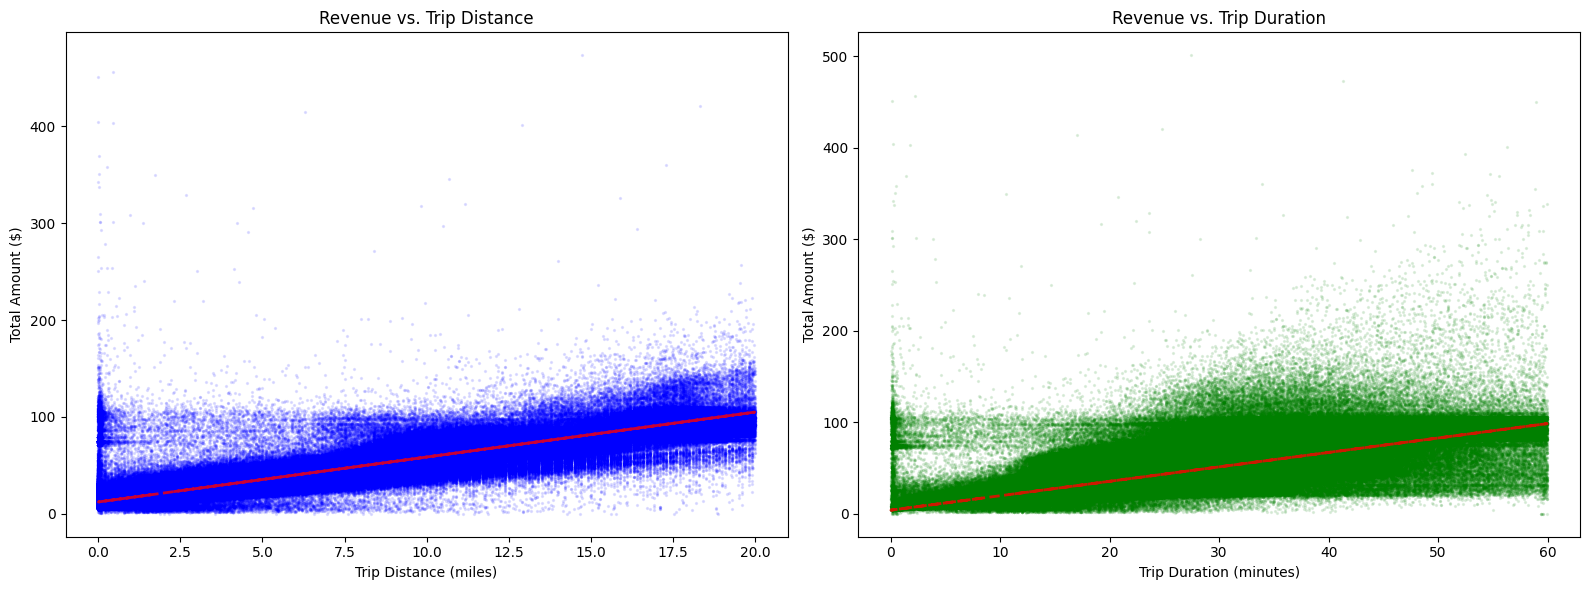

REVENUE EFFICIENCY ANALYSIS
Average revenue per mile: $22.71
Average revenue per hour: $171.79
Median revenue per mile: $11.70
Median revenue per hour: $112.80


In [20]:
# Create a scatter plot to analyze relationship between trip components
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue vs. Distance
distance_filtered = df_clean[df_clean['trip_distance'] < 20]  # Filter extreme values

# Convert to float64 for polyfit calculation
x_dist = distance_filtered['trip_distance'].astype('float64')
y_dist = distance_filtered['total_amount'].astype('float64')

axes[0].scatter(x_dist, y_dist, alpha=0.1, s=2, color='blue')
axes[0].set_xlabel('Trip Distance (miles)')
axes[0].set_ylabel('Total Amount ($)')
axes[0].set_title('Revenue vs. Trip Distance')

# Add a trend line with float64 data
z = np.polyfit(x_dist, y_dist, 1)
p = np.poly1d(z)
axes[0].plot(x_dist, p(x_dist), "r--", alpha=0.8, linewidth=2)

# Revenue vs. Duration
duration_filtered = df_clean[df_clean['trip_duration'] < 60]  # Filter extreme values

# Convert to float64 for polyfit calculation
x_dur = duration_filtered['trip_duration'].astype('float64')
y_dur = duration_filtered['total_amount'].astype('float64')

axes[1].scatter(x_dur, y_dur, alpha=0.1, s=2, color='green')
axes[1].set_xlabel('Trip Duration (minutes)')
axes[1].set_ylabel('Total Amount ($)')
axes[1].set_title('Revenue vs. Trip Duration')

# Add a trend line with float64 data
z = np.polyfit(x_dur, y_dur, 1)
p = np.poly1d(z)
axes[1].plot(x_dur, p(x_dur), "r--", alpha=0.8, linewidth=2)

plt.tight_layout()
plt.show()

# Calculate revenue efficiency metrics
print("REVENUE EFFICIENCY ANALYSIS")
print("=" * 40)
print(f"Average revenue per mile: ${df_clean['revenue_per_mile'].astype('float64').mean():.2f}")
print(f"Average revenue per hour: ${df_clean['revenue_per_hour'].astype('float64').mean():.2f}")
print(f"Median revenue per mile: ${df_clean['revenue_per_mile'].astype('float64').median():.2f}")
print(f"Median revenue per hour: ${df_clean['revenue_per_hour'].astype('float64').median():.2f}")

Hourly Revenue Patterns

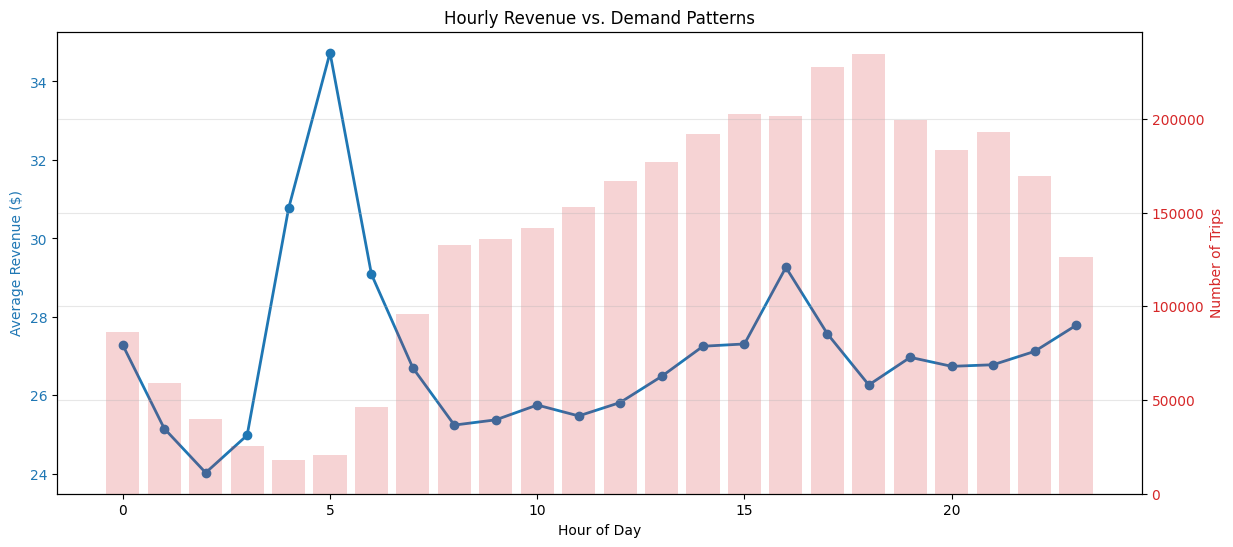

MOST PROFITABLE HOURS (Revenue per Trip)
Hour  5: $34.73 per trip
Hour  4: $30.76 per trip
Hour 16: $29.26 per trip
Hour  6: $29.09 per trip
Hour 23: $27.78 per trip


In [21]:
# Calculate average revenue by hour
hourly_revenue = df_clean.groupby('pickup_hour')['total_amount'].mean()
hourly_trips = df_clean.groupby('pickup_hour').size()

fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:blue'
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Average Revenue ($)', color=color)
ax1.plot(hourly_revenue.index, hourly_revenue.values, color=color, marker='o', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Number of Trips', color=color)  # we already handled the x-label with ax1
ax2.bar(hourly_trips.index, hourly_trips.values, alpha=0.2, color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Hourly Revenue vs. Demand Patterns')
plt.grid(alpha=0.3)
plt.show()

# Identify most profitable hours
print("MOST PROFITABLE HOURS (Revenue per Trip)")
print("=" * 45)
top_hours = hourly_revenue.sort_values(ascending=False).head(5)
for hour, revenue in top_hours.items():
    print(f"Hour {hour:2d}: ${revenue:.2f} per trip")

Speed and Congestion Analysis

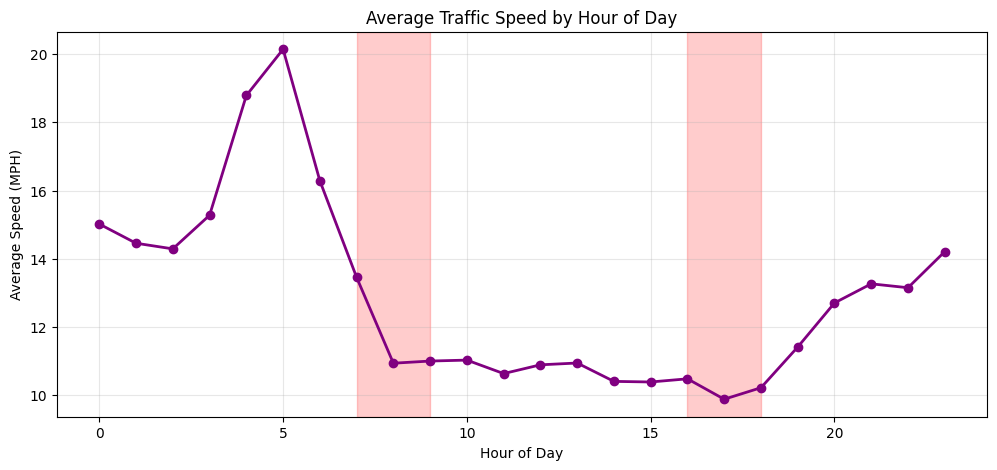

MOST CONGESTED HOURS (Lowest Average Speed)
Hour 17: 9.9 MPH
Hour 18: 10.2 MPH
Hour 15: 10.4 MPH


In [22]:
# Analyze average speed by time of day
speed_by_hour = df_clean.groupby('pickup_hour')['speed_mph'].mean()

plt.figure(figsize=(12, 5))
plt.plot(speed_by_hour.index, speed_by_hour.values, marker='o', linewidth=2, color='purple')
plt.title('Average Traffic Speed by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Speed (MPH)')
plt.grid(alpha=0.3)

# Highlight rush hours
rush_hours = [(7, 9), (16, 18)]
for start, end in rush_hours:
    plt.axvspan(start, end, alpha=0.2, color='red')

plt.show()

# Find the most congested hours
slowest_hours = speed_by_hour.sort_values().head(3)
print("MOST CONGESTED HOURS (Lowest Average Speed)")
print("=" * 45)
for hour, speed in slowest_hours.items():
    print(f"Hour {hour}: {speed:.1f} MPH")

Demand Pattern Analysis

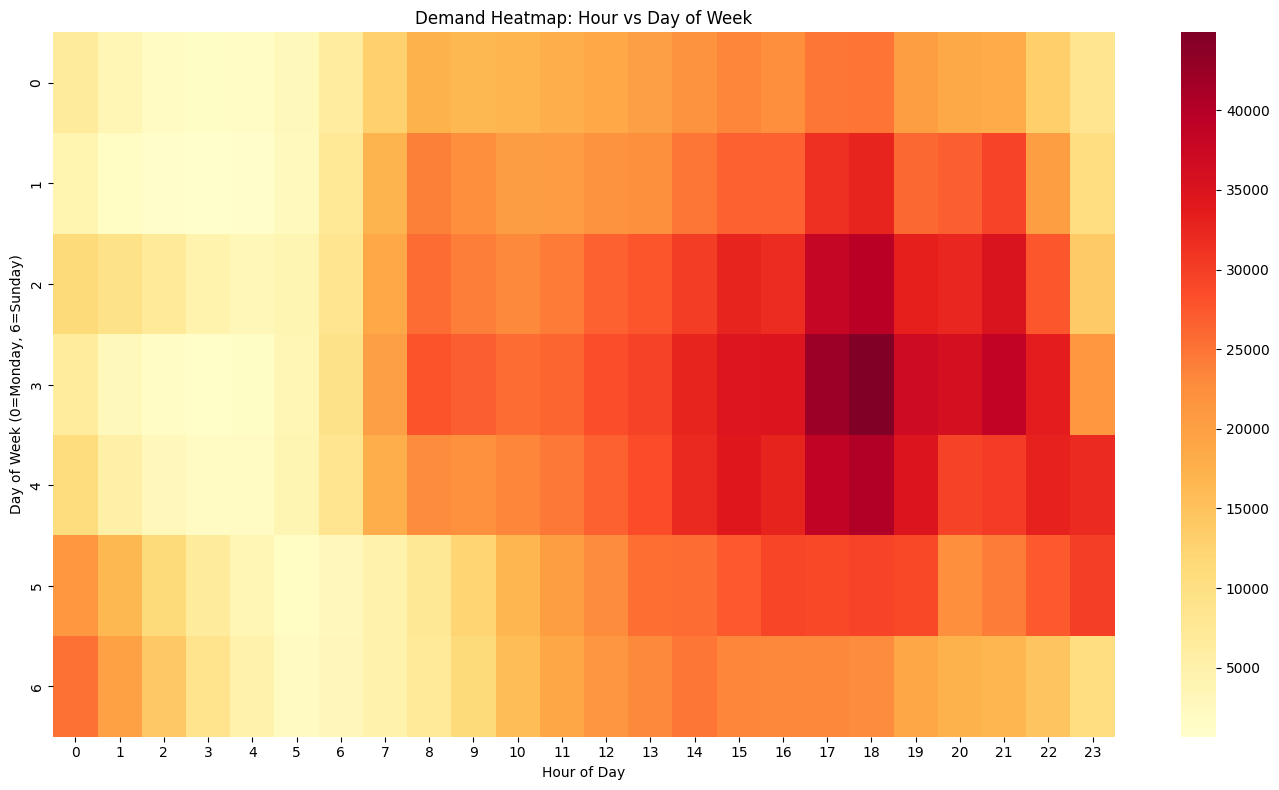

In [23]:
# Time-based demand analysis
hourly_demand = df_clean.groupby('pickup_hour').size()
daily_demand = df_clean.groupby('pickup_day').size()
dow_demand = df_clean.groupby('pickup_dayofweek').size()

# Spatial demand analysis
pickup_demand = df_clean['PULocationID'].value_counts().head(15)
dropoff_demand = df_clean['DOLocationID'].value_counts().head(15)

# Demand heatmap (hour vs day of week)
demand_heatmap_data = df_clean.groupby(['pickup_dayofweek', 'pickup_hour']).size().unstack()
plt.figure(figsize=(14, 8))
sns.heatmap(demand_heatmap_data, cmap='YlOrRd')
plt.title('Demand Heatmap: Hour vs Day of Week')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week (0=Monday, 6=Sunday)')
plt.tight_layout()
plt.show()

Revenue Optimization Analysis

In [24]:
# Calculate profitability metrics by time and location
hourly_profitability = df_clean.groupby('pickup_hour').agg({
    'total_amount': 'mean',
    'trip_duration': 'mean',
    'revenue_per_hour': 'mean'
}).reset_index()

# For location profitability, we need to count the number of trips per location
# First, let's create a temporary column for counting
df_clean['trip_count_temp'] = 1

location_profitability = df_clean.groupby('PULocationID', observed=True).agg({
    'total_amount': 'mean',
    'trip_count_temp': 'count',  # Count the number of trips
    'revenue_per_hour': 'mean'
}).reset_index()

# Rename the count column to make it more meaningful
location_profitability = location_profitability.rename(columns={'trip_count_temp': 'trip_count'})

# Identify most profitable hours and locations
top_profitable_hours = hourly_profitability.nlargest(5, 'revenue_per_hour')
top_profitable_locations = location_profitability.nlargest(10, 'revenue_per_hour')

# Display the results
print("Top 5 Most Profitable Hours:")
print(top_profitable_hours[['pickup_hour', 'revenue_per_hour']].round(2))

print("\nTop 10 Most Profitable Locations:")
print(top_profitable_locations[['PULocationID', 'revenue_per_hour', 'trip_count']].round(2))

Top 5 Most Profitable Hours:
    pickup_hour  revenue_per_hour
5             5        332.230011
4             4        279.059998
6             6        212.839996
3             3        204.199997
16           16        189.419998

Top 10 Most Profitable Locations:
    PULocationID  revenue_per_hour  trip_count
0              1      30342.419922          77
209          216       9609.200195        1995
258          265       8104.379883         544
26            27       4824.689941           3
127          134       4170.549805         593
200          207       3727.040039          67
122          129       3199.149902        1815
90            93       2772.679932         486
190          197       2340.909912        1609
216          223       2217.330078         881


## **Enhanced Predictive Modeling for Taxi Demand Forecasting**

Creating advanced features for forecasting...
Created forecasting dataset with 192,696 records
Training set: 149,184 records
Test set: 43,512 records
Training RandomForest model...
RandomForest Performance:
  MAE: 0.34
  RMSE: 2.89
  R²: 0.9973
Training GradientBoosting model...
GradientBoosting Performance:
  MAE: 1.22
  RMSE: 3.55
  R²: 0.9959
Training XGBoost model...
XGBoost Performance:
  MAE: 0.69
  RMSE: 3.38
  R²: 0.9963

Best model: RandomForest

Top 10 Most Important Features:
  trip_count_rolling_mean_3: 0.9334
  trip_count_diff_1: 0.0384
  trip_count_rolling_std_3: 0.0145
  trip_count_lag_1: 0.0088
  trip_count_rolling_std_6: 0.0018
  trip_count_lag_24: 0.0011
  trip_count_rolling_std_12: 0.0003
  trip_count_lag_3: 0.0003
  trip_count_diff_24: 0.0003
  trip_count_rolling_mean_6: 0.0001

Sample predictions for 2025-02-01:
PULocationID  hour  predicted_trip_count
           1    23                  0.00
           2    23                  0.00
           3    23              

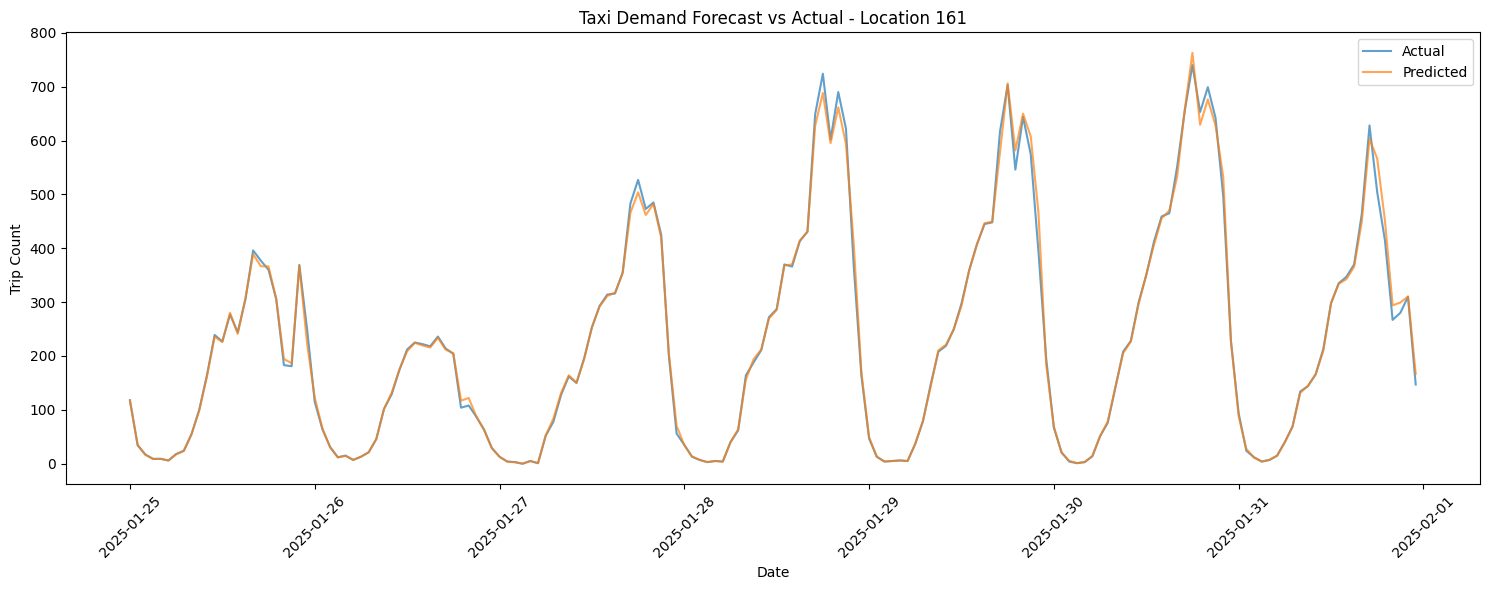

In [25]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Advanced feature engineering for time series forecasting
def create_advanced_features(df):
    # Create a complete datetime index for the entire month
    full_date_range = pd.date_range(start='2025-01-01', end='2025-01-31 23:00:00', freq='H')
    full_index = pd.MultiIndex.from_product([
        full_date_range,
        df['PULocationID'].unique()
    ], names=['datetime', 'PULocationID'])

    # Create base dataframe with all combinations
    forecast_data = pd.DataFrame(index=full_index).reset_index()

    # Aggregate original data to hourly level
    df['pickup_datetime_hour'] = df['tpep_pickup_datetime'].dt.floor('H')
    hourly_data = df.groupby(['pickup_datetime_hour', 'PULocationID']).agg({
        'VendorID': 'count',
        'total_amount': 'mean',
        'trip_duration': 'mean',
        'trip_distance': 'mean'
    }).reset_index()
    hourly_data.rename(columns={
        'VendorID': 'trip_count',
        'pickup_datetime_hour': 'datetime'
    }, inplace=True)

    # Merge with complete index to ensure all hours are represented
    forecast_data = forecast_data.merge(
        hourly_data,
        on=['datetime', 'PULocationID'],
        how='left'
    )

    # Fill missing values (hours with no trips)
    forecast_data['trip_count'] = forecast_data['trip_count'].fillna(0)
    forecast_data['total_amount'] = forecast_data['total_amount'].fillna(0)
    forecast_data['trip_duration'] = forecast_data['trip_duration'].fillna(0)
    forecast_data['trip_distance'] = forecast_data['trip_distance'].fillna(0)

    # Extract temporal features
    forecast_data['hour'] = forecast_data['datetime'].dt.hour
    forecast_data['day_of_week'] = forecast_data['datetime'].dt.dayofweek
    forecast_data['day_of_month'] = forecast_data['datetime'].dt.day
    forecast_data['is_weekend'] = (forecast_data['day_of_week'] >= 5).astype(int)

    # Create time-based features
    forecast_data['is_rush_hour'] = ((forecast_data['hour'] >= 7) & (forecast_data['hour'] <= 9)) | \
                                   ((forecast_data['hour'] >= 16) & (forecast_data['hour'] <= 19))
    forecast_data['is_night'] = (forecast_data['hour'] <= 5) | (forecast_data['hour'] >= 22)

    # Add lag features for time series analysis
    forecast_data = forecast_data.sort_values(['PULocationID', 'datetime'])

    # Create lag features (previous 1, 3, 6, 12, 24 hours)
    for lag in [1, 3, 6, 12, 24]:
        forecast_data[f'trip_count_lag_{lag}'] = forecast_data.groupby('PULocationID')['trip_count'].shift(lag)

    # Create rolling features
    for window in [3, 6, 12, 24]:
        forecast_data[f'trip_count_rolling_mean_{window}'] = forecast_data.groupby('PULocationID')['trip_count'].transform(
            lambda x: x.rolling(window=window, min_periods=1).mean()
        )
        forecast_data[f'trip_count_rolling_std_{window}'] = forecast_data.groupby('PULocationID')['trip_count'].transform(
            lambda x: x.rolling(window=window, min_periods=1).std()
        )

    # Create difference features
    forecast_data['trip_count_diff_1'] = forecast_data.groupby('PULocationID')['trip_count'].diff(1)
    forecast_data['trip_count_diff_24'] = forecast_data.groupby('PULocationID')['trip_count'].diff(24)

    # Fill NaN values created by lag operations
    forecast_data = forecast_data.fillna(method='bfill')

    return forecast_data

# Create advanced features
print("Creating advanced features for forecasting...")
forecast_data = create_advanced_features(df_clean)
print(f"Created forecasting dataset with {len(forecast_data):,} records")

# Prepare features and target
feature_columns = [
    'hour', 'day_of_week', 'day_of_month', 'is_weekend', 'is_rush_hour', 'is_night',
    'trip_count_lag_1', 'trip_count_lag_3', 'trip_count_lag_6', 'trip_count_lag_12', 'trip_count_lag_24',
    'trip_count_rolling_mean_3', 'trip_count_rolling_mean_6', 'trip_count_rolling_mean_12', 'trip_count_rolling_mean_24',
    'trip_count_rolling_std_3', 'trip_count_rolling_std_6', 'trip_count_rolling_std_12', 'trip_count_rolling_std_24',
    'trip_count_diff_1', 'trip_count_diff_24',
    'PULocationID'  # Keep as categorical
]

X = forecast_data[feature_columns]
y = forecast_data['trip_count']

# Convert location ID to category for tree-based models
X['PULocationID'] = X['PULocationID'].astype('category')

# Time-based split (use first 80% of days for training, last 20% for testing)
unique_days = sorted(forecast_data['datetime'].dt.date.unique())
split_day = unique_days[int(len(unique_days) * 0.8)]

train_mask = forecast_data['datetime'].dt.date < split_day
test_mask = forecast_data['datetime'].dt.date >= split_day

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"Training set: {len(X_train):,} records")
print(f"Test set: {len(X_test):,} records")

# Train and evaluate each model
results = {}

# RandomForest (handles categorical natively)
print("Training RandomForest model...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

results['RandomForest'] = {
    'MAE': mae_rf,
    'RMSE': rmse_rf,
    'R2': r2_rf,
    'model': rf_model
}

print(f"RandomForest Performance:")
print(f"  MAE: {mae_rf:.2f}")
print(f"  RMSE: {rmse_rf:.2f}")
print(f"  R²: {r2_rf:.4f}")

# GradientBoosting (handles categorical natively)
print("Training GradientBoosting model...")
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

results['GradientBoosting'] = {
    'MAE': mae_gb,
    'RMSE': rmse_gb,
    'R2': r2_gb,
    'model': gb_model
}

print(f"GradientBoosting Performance:")
print(f"  MAE: {mae_gb:.2f}")
print(f"  RMSE: {rmse_gb:.2f}")
print(f"  R²: {r2_gb:.4f}")

# XGBoost (needs categorical conversion)
print("Training XGBoost model...")
# Convert categorical column to integer codes for XGBoost
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
X_train_xgb['PULocationID'] = X_train_xgb['PULocationID'].cat.codes
X_test_xgb['PULocationID'] = X_test_xgb['PULocationID'].cat.codes

xgb_model = xgb.XGBRegressor(random_state=42, n_jobs=-1)
xgb_model.fit(X_train_xgb, y_train)
y_pred_xgb = xgb_model.predict(X_test_xgb)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

results['XGBoost'] = {
    'MAE': mae_xgb,
    'RMSE': rmse_xgb,
    'R2': r2_xgb,
    'model': xgb_model
}

print(f"XGBoost Performance:")
print(f"  MAE: {mae_xgb:.2f}")
print(f"  RMSE: {rmse_xgb:.2f}")
print(f"  R²: {r2_xgb:.4f}")

# Find the best model
best_model_name = min(results, key=lambda x: results[x]['RMSE'])
best_model = results[best_model_name]['model']
print(f"\nBest model: {best_model_name}")

# Feature importance analysis
if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': feature_columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)

    print("\nTop 10 Most Important Features:")
    for i, row in feature_importance.head(10).iterrows():
        print(f"  {row['feature']}: {row['importance']:.4f}")

# Create predictions for the next day (demonstration)
last_date = forecast_data['datetime'].max()
next_day = last_date + pd.Timedelta(days=1)
next_day_data = forecast_data[forecast_data['datetime'] == last_date].copy()

# Update datetime to next day
next_day_data['datetime'] = next_day_data['datetime'] + pd.Timedelta(days=1)
next_day_data['day_of_month'] = next_day_data['datetime'].dt.day
next_day_data['day_of_week'] = next_day_data['datetime'].dt.dayofweek
next_day_data['is_weekend'] = (next_day_data['day_of_week'] >= 5).astype(int)

# Update lag features (this would need a more sophisticated approach in production)
# For demonstration, we'll use the same values
next_day_X = next_day_data[feature_columns]
next_day_predictions = best_model.predict(next_day_X)

# Add predictions to dataframe
next_day_data['predicted_trip_count'] = next_day_predictions

print(f"\nSample predictions for {next_day.date()}:")
sample_predictions = next_day_data[['PULocationID', 'hour', 'predicted_trip_count']].head(10)
print(sample_predictions.to_string(index=False))

# Visualize predictions vs actual for a sample location
sample_location = 161  # Manhattan midtown
sample_data = forecast_data[forecast_data['PULocationID'] == sample_location].copy()
sample_data = sample_data.sort_values('datetime')

# For the test period, add predictions
sample_test = sample_data[sample_data['datetime'].dt.date >= split_day].copy()
sample_test['predicted'] = best_model.predict(sample_test[feature_columns])

# Plot actual vs predicted
plt.figure(figsize=(15, 6))
plt.plot(sample_test['datetime'], sample_test['trip_count'], label='Actual', alpha=0.7)
plt.plot(sample_test['datetime'], sample_test['predicted'], label='Predicted', alpha=0.7)
plt.title(f'Taxi Demand Forecast vs Actual - Location {sample_location}')
plt.xlabel('Date')
plt.ylabel('Trip Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Cluster Analysis for Zone Segmentation**

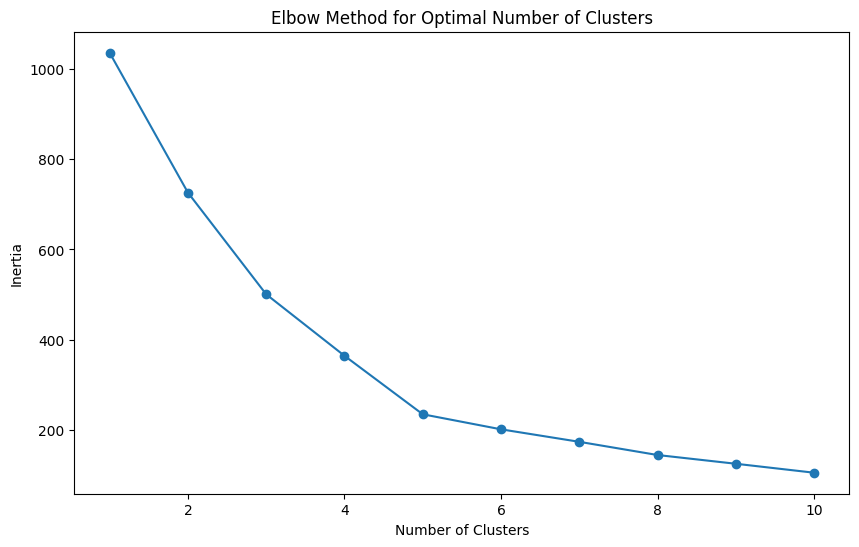

Cluster Summary:


,trip_count,total_amount,revenue_per_hour,speed_mph,zone_count
cluster,,,,,
0,2786.430000,31.884937,224.837418,18.108608,200
1,105.000000,74.031075,12064.860352,235.078552,3
2,9070.884615,64.258469,1468.411499,28.398882,26
3,81131.633333,22.524099,144.546555,10.225158,30


In [26]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare data for clustering
cluster_data = df_clean.groupby('PULocationID').agg({
    'total_amount': 'mean',
    'trip_duration': 'mean',
    'VendorID': 'count',
    'revenue_per_hour': 'mean',
    'speed_mph': 'mean'
}).reset_index()
cluster_data.rename(columns={'VendorID': 'trip_count'}, inplace=True)

# Select features for clustering
X_cluster = cluster_data[['trip_count', 'total_amount', 'revenue_per_hour', 'speed_mph']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Determine optimal number of clusters using elbow method
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.show()

# Apply K-means clustering with optimal k
optimal_k = 4  # Based on elbow method
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_data['cluster'] = kmeans.fit_predict(X_scaled)

# Analyze cluster characteristics
cluster_summary = cluster_data.groupby('cluster').agg({
    'trip_count': 'mean',
    'total_amount': 'mean',
    'revenue_per_hour': 'mean',
    'speed_mph': 'mean',
    'PULocationID': 'count'
}).rename(columns={'PULocationID': 'zone_count'})

print("Cluster Summary:")
display(cluster_summary)